# Sales & Customer Analytics Dashboard

**Portfolio project on synthetic retail data** — SQL KPI queries, Python EDA with
RFM customer segmentation, and a KPI dashboard.

> **Data note:** every table is synthetic, generated by `src/generate_data.py`
> (seeded with `random_state=42`). No real company, customer, or transaction is
> represented here.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, "../src")

import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from data_cleaning import load_and_clean
import analysis as A

sns.set_theme(style="whitegrid", palette="deep")

orders, customers, products = load_and_clean("../data")

Cleaning report:
  duplicate_orders_removed: 0
  max_line_total_drift_usd: 0.0
  orders: 12000
  customers: 2500
  products: 60
  date_range: (datetime.date(2023, 1, 1), datetime.date(2024, 12, 31))


## 1. Data cleaning

`load_and_clean()` parses dates, enforces dtypes, drops duplicate orders,
validates key integrity (no null keys, non-negative amounts, `line_total`
recomputed from price × quantity × discount), and enriches orders with
`order_month` / `order_year`. The cleaning report above shows zero duplicates
and zero drift — the synthetic generator is internally consistent.

In [2]:
print("orders   :", orders.shape)
print("customers:", customers.shape)
print("products :", products.shape)
print("\norders dtypes:\n", orders.dtypes)
print("\nNull values in orders:\n", orders.isna().sum())
orders.head(3).to_string(index=False)

orders   : (12000, 11)
customers: (2500, 5)
products : (60, 4)

orders dtypes:
 order_id                  str
order_date     datetime64[us]
customer_id               str
product_id                str
quantity                int64
unit_price            float64
discount              float64
line_total            float64
channel                   str
order_month               str
order_year              int32
dtype: object

Null values in orders:
 order_id       0
order_date     0
customer_id    0
product_id     0
quantity       0
unit_price     0
discount       0
line_total     0
channel        0
order_month    0
order_year     0
dtype: int64


'order_id order_date customer_id product_id  quantity  unit_price  discount  line_total  channel order_month  order_year\n O111494 2023-01-01       C1581       P016         3       89.74       0.1      242.30 In-Store     2023-01        2023\n O102657 2023-01-01       C3479       P059         5       68.72       0.0      343.60 In-Store     2023-01        2023\n O103359 2023-01-01       C2899       P006         2      236.84       0.2      378.94 In-Store     2023-01        2023'

## 2. KPI overview

Headline metrics for the two-year window (2023-2024).

In [3]:
rep = A.repeat_customer_stats(orders)
kpis = pd.DataFrame({
    "Metric": [
        "Total Revenue", "Total Orders", "Average Order Value",
        "Purchasing Customers", "Repeat-buyer Rate",
        "Repeat-buyer Revenue Share", "Top Region (Revenue)",
        "Top Category (Revenue)",
    ],
    "Value": [
        f"${A.total_revenue(orders):,.2f}",
        f"{A.total_orders(orders):,}",
        f"${A.average_order_value(orders):,.2f}",
        f"{A.unique_customers(orders):,}",
        f"{rep['repeat_rate']:.1%}",
        f"{rep['repeater_revenue_share']:.1%}",
        A.revenue_by_region(orders, customers).iloc[0]['region'],
        A.revenue_by_category(orders, products).iloc[0]['category'],
    ],
})
kpis

,Metric,Value
0,Total Revenue,"$2,322,744.42"
1,Total Orders,"12,000"
2,Average Order Value,$193.56
3,Purchasing Customers,"1,903"
4,Repeat-buyer Rate,83.9%
5,Repeat-buyer Revenue Share,97.3%
6,Top Region (Revenue),North
7,Top Category (Revenue),Electronics


## 3. Revenue trend — seasonality

Monthly revenue shows a strong November/December holiday spike and a smaller
summer bump, with February as the slowest month — exactly the seasonality
baked into the generator.

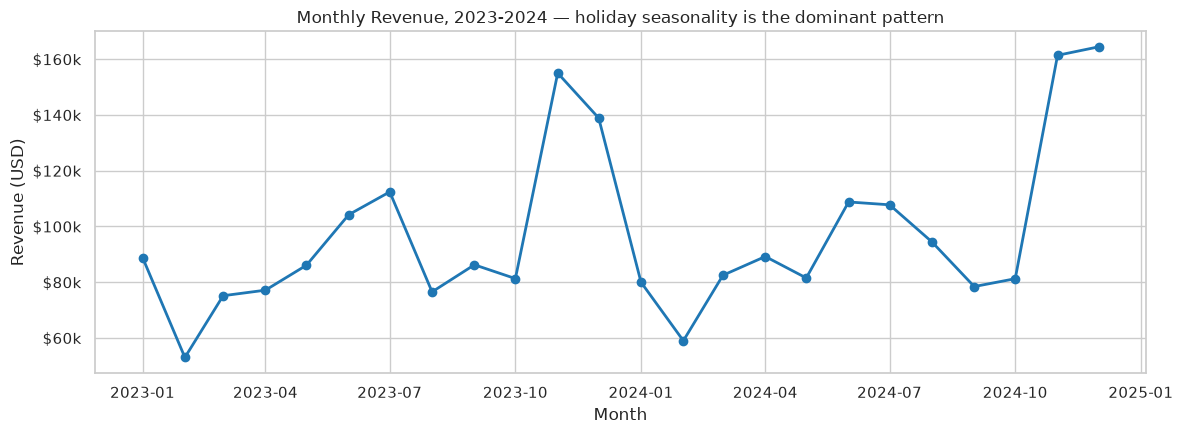

,order_month,revenue,orders
18,2024-07,107726.43,561
19,2024-08,94425.23,454
20,2024-09,78405.26,416
21,2024-10,81219.13,415
22,2024-11,161350.81,792
23,2024-12,164380.90,832


In [4]:
monthly = A.monthly_revenue(orders)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(pd.to_datetime(monthly["order_month"]), monthly["revenue"],
        marker="o", linewidth=2, color="#1f77b4")
ax.set_title("Monthly Revenue, 2023-2024 — holiday seasonality is the dominant pattern")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (USD)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x/1000:.0f}k"))
fig.tight_layout()
fig.savefig("../images/revenue_trend.png", dpi=150)
plt.show()

monthly.tail(6)

## 4. Product category performance

Electronics dominates revenue — higher unit prices outweigh lower unit counts.
Beauty is the long tail: many small tickets.

/tmp/ipykernel_7292/1816685728.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat, x="revenue", y="category", ax=ax, palette="viridis",


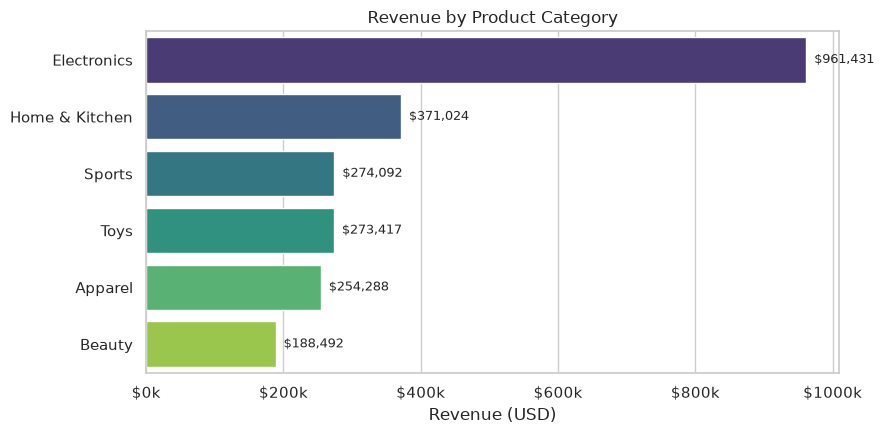

,category,revenue,orders,avg_order_value
2,Electronics,"$961,431.33",1914,$502.32
3,Home & Kitchen,"$371,023.86",2032,$182.59
4,Sports,"$274,092.14",1798,$152.44
5,Toys,"$273,417.16",2366,$115.56
0,Apparel,"$254,288.10",2081,$122.20
1,Beauty,"$188,491.83",1809,$104.20


In [5]:
cat = A.revenue_by_category(orders, products)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=cat, x="revenue", y="category", ax=ax, palette="viridis",
            order=cat["category"])
ax.set_title("Revenue by Product Category")
ax.set_xlabel("Revenue (USD)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x/1000:.0f}k"))
for i, v in enumerate(cat["revenue"]):
    ax.text(v, i, f"  ${v:,.0f}", va="center", fontsize=9)
fig.tight_layout()
fig.savefig("../images/category_revenue.png", dpi=150)
plt.show()

cat.style.format({"revenue": "${:,.2f}", "avg_order_value": "${:,.2f}"})

## 5. Regional & channel performance

The North region leads on revenue; Online is the largest channel by both
orders and revenue.

/tmp/ipykernel_7292/155841171.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=reg, x="region", y="revenue", ax=ax, palette="deep",


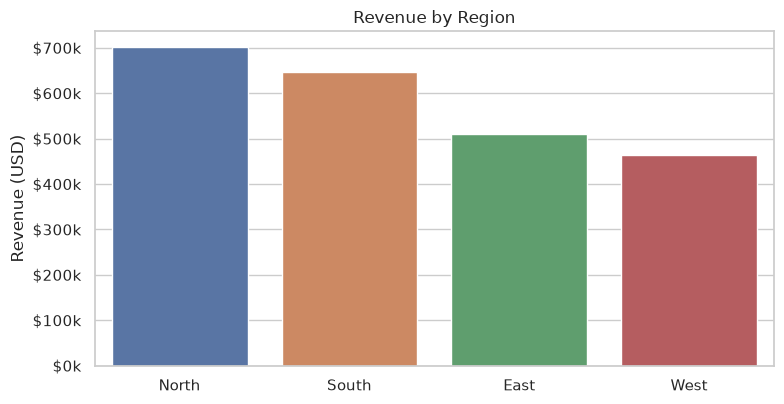

Revenue by region:


,region,revenue,orders,customers
1,North,"$700,980.03",3656,569
2,South,"$647,055.01",3321,515
0,East,"$510,814.64",2565,415
3,West,"$463,894.74",2458,404



Channel performance:


,channel,revenue,orders,avg_order_value
2,Online,"$1,050,865.29",5361,$196.02
0,In-Store,"$829,836.24",4257,$194.93
1,Mobile App,"$442,042.89",2382,$185.58


In [6]:
reg = A.revenue_by_region(orders, customers)

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.barplot(data=reg, x="region", y="revenue", ax=ax, palette="deep",
            order=reg["region"])
ax.set_title("Revenue by Region")
ax.set_xlabel("")
ax.set_ylabel("Revenue (USD)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x/1000:.0f}k"))
fig.tight_layout()
fig.savefig("../images/region_revenue.png", dpi=150)
plt.show()

print("Revenue by region:")
display(reg.style.format({"revenue": "${:,.2f}"}))
print("\nChannel performance:")
display(A.channel_performance(orders).style.format(
    {"revenue": "${:,.2f}", "avg_order_value": "${:,.2f}"}))

## 6. Repeat vs one-time customers

A loyalty-skewed base: the large majority of purchasing customers buy more
than once, and repeat buyers drive nearly all revenue.

Repeat buyers : 1,597 (83.9% of purchasing customers)
One-time      : 306
Revenue share from repeat buyers: 97.3%


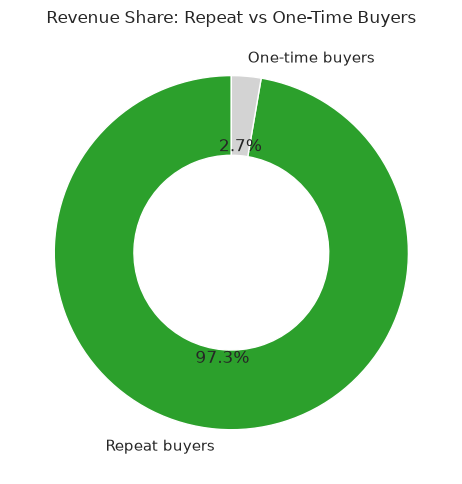

In [7]:
rep = A.repeat_customer_stats(orders)
print(f"Repeat buyers : {rep['repeat_customers']:,} "
      f"({rep['repeat_rate']:.1%} of purchasing customers)")
print(f"One-time      : {rep['one_time_customers']:,}")
print(f"Revenue share from repeat buyers: {rep['repeater_revenue_share']:.1%}")

fig, ax = plt.subplots(figsize=(5, 5))
ax.pie([rep["repeater_revenue_share"], 1 - rep["repeater_revenue_share"]],
       labels=["Repeat buyers", "One-time buyers"],
       autopct="%1.1f%%", startangle=90,
       colors=["#2ca02c", "#d3d3d3"], wedgeprops={"width": 0.45})
ax.set_title("Revenue Share: Repeat vs One-Time Buyers")
fig.tight_layout()
fig.savefig("../images/repeat_vs_onetime.png", dpi=150)
plt.show()

## 7. RFM customer segmentation

Customers are scored 1-5 on Recency, Frequency, and Monetary value (quintiles
as of 2024-12-31) and grouped into five segments, from Champions to Lost.

/tmp/ipykernel_7292/3385148643.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=order, y=[seg_counts[c] for c in order], ax=ax, palette="coolwarm")


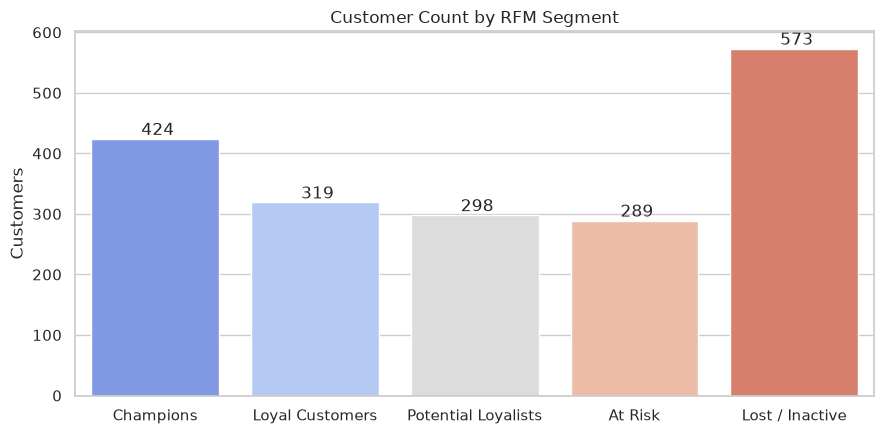

Average lifetime spend by segment:


,segment,customers,avg_monetary
1,Champions,424,"$2,595.37"
3,Loyal Customers,319,"$1,628.56"
4,Potential Loyalists,298,"$1,093.26"
0,At Risk,289,$705.31
2,Lost / Inactive,573,$302.22


In [8]:
rfm = A.rfm_segmentation(orders)
order = ["Champions", "Loyal Customers", "Potential Loyalists",
         "At Risk", "Lost / Inactive"]
seg_counts = rfm["segment"].value_counts()

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=order, y=[seg_counts[c] for c in order], ax=ax, palette="coolwarm")
ax.set_title("Customer Count by RFM Segment")
ax.set_xlabel("")
ax.set_ylabel("Customers")
for i, c in enumerate(order):
    ax.text(i, seg_counts[c], f" {seg_counts[c]:,}", ha="center", va="bottom")
fig.tight_layout()
fig.savefig("../images/rfm_segments.png", dpi=150)
plt.show()

print("Average lifetime spend by segment:")
display(A.customer_lifetime_value_by_segment(rfm).style.format(
    {"avg_monetary": "${:,.2f}"}))

## 8. SQL analysis

The same KPIs expressed as SQLite queries (`sql/analysis_queries.sql`),
executed here against the CSVs loaded into an in-memory database —
verifying the Python results independently.

In [9]:
con = sqlite3.connect(":memory:")
pd.read_csv("../data/orders.csv").to_sql("orders", con, index=False)
pd.read_csv("../data/customers.csv").to_sql("customers", con, index=False)
pd.read_csv("../data/products.csv").to_sql("products", con, index=False)

lines = [ln for ln in open("../sql/analysis_queries.sql")
         if not ln.strip().startswith("--")]
stmts = [s.strip() for s in "".join(lines).split(";") if s.strip()]
print(f"{len(stmts)} queries found in sql/analysis_queries.sql\n")

for i, stmt in enumerate(stmts, 1):
    df = pd.read_sql(stmt, con)
    print(f"--- Query {i} ({len(df)} rows) ---")
    display(df.head(10) if len(df) > 10 else df)
    print()

6 queries found in sql/analysis_queries.sql

--- Query 1 (96 rows) ---


,order_month,region,orders,revenue,avg_order_value
0,2023-01,East,87,18683.45,214.75
1,2023-01,North,138,27527.90,199.48
2,2023-01,South,121,21747.96,179.74
3,2023-01,West,93,20864.17,224.35
4,2023-02,East,66,11137.35,168.75
5,2023-02,North,83,13311.74,160.38
6,2023-02,South,96,18429.35,191.97
7,2023-02,West,59,10100.37,171.19
8,2023-03,East,76,15726.85,206.93
9,2023-03,North,117,20226.55,172.88



--- Query 2 (10 rows) ---


,product_id,product_name,category,orders,units_sold,revenue
0,P007,Ultra Speaker,Electronics,275,665,184570.45
1,P006,Compact Headphones,Electronics,278,699,159094.86
2,P008,Essential Charger,Electronics,269,637,158138.11
3,P002,Pro Speaker,Electronics,233,576,131446.17
4,P004,Premium Smart Watch,Electronics,293,680,113881.33
5,P001,Deluxe Headphones,Electronics,218,518,92768.63
6,P038,Deluxe Water Bottle,Sports,173,425,59702.56
7,P015,Essential Organizer,Home & Kitchen,231,555,59675.25
8,P018,Classic Lamp,Home & Kitchen,234,537,55257.27
9,P003,Classic Charger,Electronics,205,479,55033.82



--- Query 3 (2 rows) ---


...

,month,revenue_2023,revenue_2024,yoy_growth_pct
0,01,88823.48,79959.03,-10.0
1,02,52978.81,58963.40,11.3
2,03,75117.73,82464.82,9.8
3,04,77108.45,89179.60,15.7
4,05,86049.93,81485.46,-5.3
5,06,104190.75,108747.80,4.4
6,07,112359.95,107726.43,-4.1
7,08,76496.48,94425.23,23.4
8,09,86211.20,78405.26,-9.1
9,10,81263.26,81219.13,-0.1



--- Query 5 (6 rows) ---


,category,orders,revenue,avg_order_value
0,Electronics,1914,961431.33,502.32
1,Home & Kitchen,2032,371023.86,182.59
2,Sports,1798,274092.14,152.44
3,Toys,2366,273417.16,115.56
4,Apparel,2081,254288.10,122.20
5,Beauty,1809,188491.83,104.20



--- Query 6 (3 rows) ---


,channel,orders,revenue,avg_order_value
0,Online,5361,1050865.29,196.02
1,In-Store,4257,829836.24,194.93
2,Mobile App,2382,442042.89,185.58


## 9. KPI dashboard — overview figure

A single overview figure combining the headline KPI tiles with the monthly
revenue trend, mimicking the top of a BI dashboard.

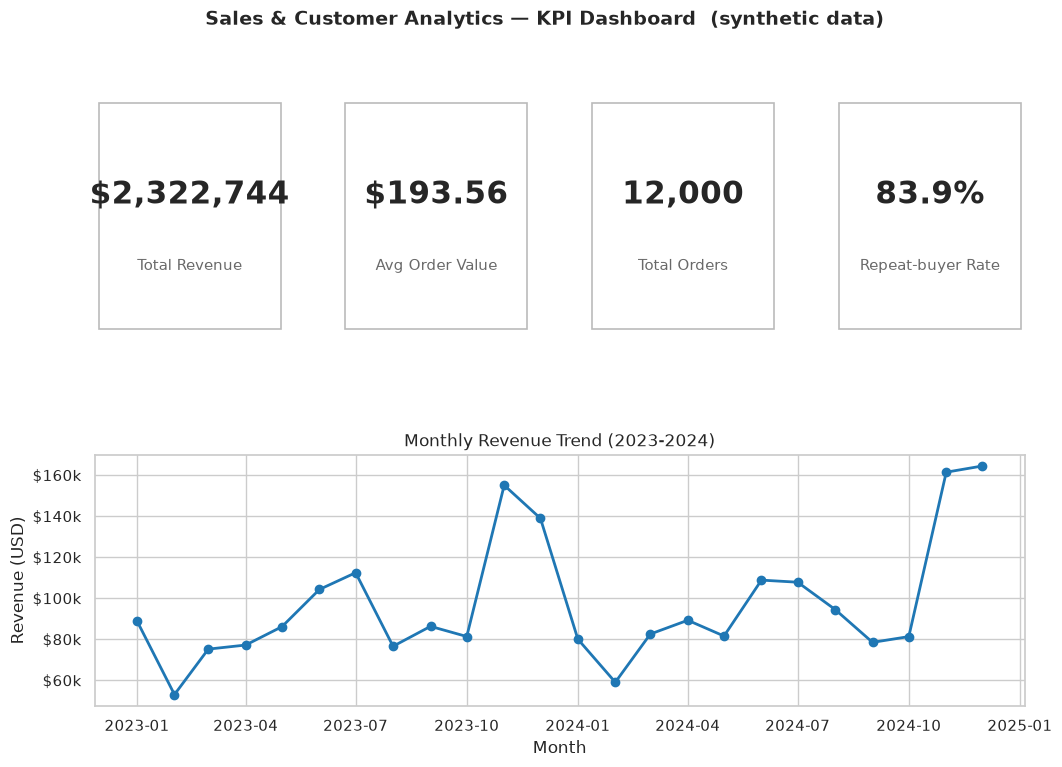

In [10]:
from matplotlib.gridspec import GridSpec

rev = A.total_revenue(orders)
aov = A.average_order_value(orders)
n_orders = A.total_orders(orders)
rr = A.repeat_customer_stats(orders)["repeat_rate"]

fig = plt.figure(figsize=(12, 8))
gs = GridSpec(2, 4, figure=fig, hspace=0.45, wspace=0.3)

tiles = [("Total Revenue", f"${rev:,.0f}"),
         ("Avg Order Value", f"${aov:,.2f}"),
         ("Total Orders", f"{n_orders:,}"),
         ("Repeat-buyer Rate", f"{rr:.1%}")]
for j, (label, val) in enumerate(tiles):
    ax = fig.add_subplot(gs[0, j])
    ax.axis("off")
    ax.add_patch(plt.Rectangle((0.02, 0.05), 0.96, 0.9,
                               fill=False, edgecolor="#bbbbbb", lw=1.2))
    ax.text(0.5, 0.58, val, ha="center", va="center",
            fontsize=22, fontweight="bold", transform=ax.transAxes)
    ax.text(0.5, 0.30, label, ha="center", va="center",
            fontsize=11, color="dimgray", transform=ax.transAxes)

ax2 = fig.add_subplot(gs[1, :])
ax2.plot(pd.to_datetime(monthly["order_month"]), monthly["revenue"],
         marker="o", linewidth=2, color="#1f77b4")
ax2.set_title("Monthly Revenue Trend (2023-2024)")
ax2.set_xlabel("Month")
ax2.set_ylabel("Revenue (USD)")
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x/1000:.0f}k"))

fig.suptitle("Sales & Customer Analytics — KPI Dashboard  (synthetic data)",
             fontsize=14, fontweight="bold")
fig.savefig("../images/kpi_dashboard.png", dpi=150)
plt.show()

## 10. Key insights

Printed from the computed values above — no hand-typed numbers.

In [11]:
yoy = A.yoy_monthly_growth(orders)
dec = yoy[yoy["month"] == "12"].iloc[0]
nov = yoy[yoy["month"] == "11"].iloc[0]
cat = A.revenue_by_category(orders, products)
reg = A.revenue_by_region(orders, customers)
rep = A.repeat_customer_stats(orders)
rfm = A.rfm_segmentation(orders)
top_seg = rfm["segment"].value_counts().idxmax()

print(f"1. Two-year revenue totals ${A.total_revenue(orders):,.2f} across "
      f"{A.total_orders(orders):,} orders "
      f"(AOV ${A.average_order_value(orders):,.2f}).")
print(f"2. Holiday seasonality dominates: December revenue grew "
      f"{dec['yoy_growth_pct']:.1f}% YoY and November {nov['yoy_growth_pct']:.1f}%.")
print(f"3. {cat.iloc[0]['category']} is the top category at "
      f"${cat.iloc[0]['revenue']:,.0f} "
      f"({cat.iloc[0]['revenue']/A.total_revenue(orders):.1%} of revenue).")
print(f"4. The {reg.iloc[0]['region']} region leads with "
      f"${reg.iloc[0]['revenue']:,.0f} "
      f"({reg.iloc[0]['revenue']/A.total_revenue(orders):.1%} of revenue).")
print(f"5. {rep['repeat_customers']:,} repeat buyers ({rep['repeat_rate']:.1%} of "
      f"purchasing customers) generate {rep['repeater_revenue_share']:.1%} of revenue "
      f"— retention is the growth lever.")
print(f"6. RFM segmentation flags {len(rfm[rfm['segment']=='At Risk']):,} At-Risk "
      f"customers for win-back campaigns; the largest segment is '{top_seg}'.")

1. Two-year revenue totals $2,322,744.42 across 12,000 orders (AOV $193.56).
2. Holiday seasonality dominates: December revenue grew 18.4% YoY and November 4.1%.
3. Electronics is the top category at $961,431 (41.4% of revenue).
4. The North region leads with $700,980 (30.2% of revenue).
5. 1,597 repeat buyers (83.9% of purchasing customers) generate 97.3% of revenue — retention is the growth lever.
6. RFM segmentation flags 289 At-Risk customers for win-back campaigns; the largest segment is 'Lost / Inactive'.
